In [19]:
import torch
import torch.nn as nn

# 1. Automatically select GPU if available, otherwise fall back to CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

if device.type == "cuda":
  print(f"GPU Name: {torch.cuda.get_device_name(0)}")
  print(f"VRAM Available: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

Using device: cuda
GPU Name: NVIDIA GeForce RTX 4070
VRAM Available: 11.99 GB


Train Dir: enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train\train | Exists: True
CSV Path: enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train_labels.csv | Exists: True
Successfully loaded CSV with 63660 total rows.
--- Number of Entries Per Class ---
class
CatEye      13884
DogEye      11580
CatNose      6942
CatFace      6942
CatMouth     6942
DogMouth     5790
DogFace      5790
DogNose      5790
Name: count, dtype: int64


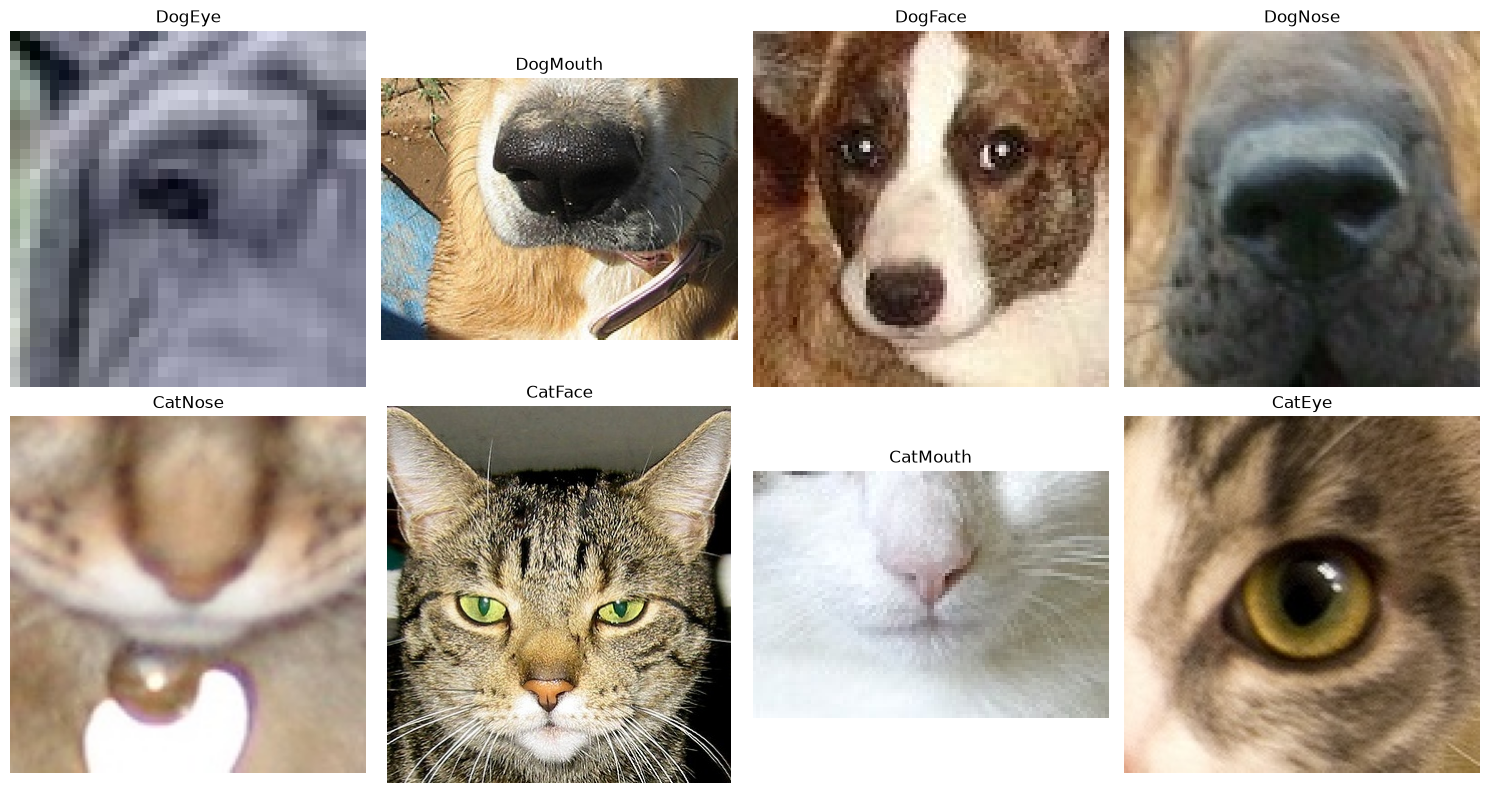

In [20]:
import os
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

# 1. Auto-detect dataset folder and correct the nested train path
base_folder = [f for f in os.listdir('.') if f.startswith('enge-')][0]
train_dir = os.path.join(base_folder, 'train', 'train')  # Fixed double nested path
train_labels_path = os.path.join(base_folder, 'train_labels.csv')

print('Train Dir:', train_dir, '| Exists:', os.path.exists(train_dir))
print('CSV Path:', train_labels_path, '| Exists:', os.path.exists(train_labels_path))

# 2. Load labels
df_labels = pd.read_csv(train_labels_path)
print(f'Successfully loaded CSV with {len(df_labels)} total rows.')

# 3. Helper function to find images with zero-padding
def get_image_path(row_id, directory):
  str_id = str(row_id).split('.')[0].strip()
  base_name = str_id.zfill(5) if str_id.isdigit() else str_id
  for ext in ['.jpg', '.png', '.jpeg', '']:
    path = os.path.join(directory, base_name + ext)
    if os.path.exists(path):
      return path
  return None

# Count the number of entries per class
class_counts = df_labels['class'].value_counts()

print('--- Number of Entries Per Class ---')
print(class_counts)

# 4. Display sample images from each unique class
unique_classes = df_labels.iloc[:, 1].unique()
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
axes = axes.flatten()

for i, class_name in enumerate(unique_classes):
  if i < len(axes):
    sample_row = df_labels[df_labels.iloc[:, 1] == class_name].iloc[0]
    img_id = sample_row.iloc[0]
    img_path = get_image_path(img_id, train_dir)

    if img_path and os.path.exists(img_path):
      img = Image.open(img_path)
      axes[i].imshow(img)
      axes[i].set_title(f'{class_name}')
    else:
      axes[i].set_title(f'{class_name}\n(Not found: {img_id})')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [21]:
from PIL import Image
import os

print("--- Running Data Quality Inspection ---")
image_sizes = []
corrupted_files = []

# Loop through all rows in your labels dataframe
for idx, row in df_labels.iterrows():
  img_id = row.iloc[0]
  img_path = get_image_path(img_id, train_dir)

  if img_path and os.path.exists(img_path):
    try:
      with Image.open(img_path) as img:
        image_sizes.append(img.size)  # Collects (width, height)
    except Exception as e:
      corrupted_files.append((img_id, str(e)))
  else:
    corrupted_files.append((img_id, "File missing"))

# 1. Check Image Size Consistency
if image_sizes:
  widths, heights = zip(*image_sizes)
  print(f"Total images successfully checked: {len(image_sizes)}")
  print(
      f"Width range: min = {min(widths)}, max = {max(widths)} (Consistent:"
      f" {min(widths) == max(widths)})"
  )
  print(
      f"Height range: min = {min(heights)}, max = {max(heights)} (Consistent:"
      f" {min(heights) == max(heights)})"
  )
else:
  print("No images were found to analyze sizes.")

# 2. Check for Corrupted or Missing Files
print(f"Corrupted or missing files found: {len(corrupted_files)}")
if corrupted_files:
  print("Sample issues:", corrupted_files[:5])
else:
  print("All files opened successfully without corruption!")

--- Running Data Quality Inspection ---
Total images successfully checked: 63660
Width range: min = 4, max = 2219 (Consistent: False)
Height range: min = 4, max = 2219 (Consistent: False)
Corrupted or missing files found: 0
All files opened successfully without corruption!


In [22]:
import hashlib
import os
from PIL import Image

print("--- Scanning for Duplicate Images ---")
image_hashes = {}
duplicates = []

for idx, row in df_labels.iterrows():
  img_id = row.iloc[0]
  img_path = get_image_path(img_id, train_dir)

  if img_path and os.path.exists(img_path):
    try:
      # Read binary file contents to generate an exact hash
      with open(img_path, "rb") as f:
        file_hash = hashlib.md5(f.read()).hexdigest()

      if file_hash in image_hashes:
        duplicates.append((img_id, image_hashes[file_hash]))
      else:
        image_hashes[file_hash] = img_id
    except Exception as e:
      pass

print(f"Total unique images found: {len(image_hashes)}")
print(f"Total duplicate images found: {len(duplicates)}")

if duplicates:
  print("\nSample duplicate pairs (Image ID -> Duplicate of ID):")
  for dup in duplicates[:5]:
    print(f"  Image {dup[0]} is a duplicate of Image {dup[1]}")
else:
  print("\nGreat news! No exact duplicate images were found in the dataset.")

--- Scanning for Duplicate Images ---
Total unique images found: 63645
Total duplicate images found: 15

Sample duplicate pairs (Image ID -> Duplicate of ID):
  Image 6903 is a duplicate of Image 356
  Image 12150 is a duplicate of Image 7219
  Image 21960 is a duplicate of Image 16730
  Image 40256 is a duplicate of Image 25436
  Image 42280 is a duplicate of Image 3365


In [23]:
import hashlib
import os
from PIL import Image
from sklearn.model_selection import train_test_split
import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

# 1. Auto-detect dataset paths
base_folder = [f for f in os.listdir('.') if f.startswith('enge-')][0]
train_dir = os.path.join(base_folder, 'train', 'train')
train_labels_path = os.path.join(base_folder, 'train_labels.csv')

df_labels = pd.read_csv(train_labels_path)


# 2. Helper Image Path Function
def get_image_path(row_id, directory):
  str_id = str(row_id).split('.')[0].strip()
  base_name = str_id.zfill(5) if str_id.isdigit() else str_id
  for ext in ['.jpg', '.png', '.jpeg', '']:
    path = os.path.join(directory, base_name + ext)
    if os.path.exists(path):
      return path
  return None


# 3. Remove Exact Duplicate Images via MD5 Hashing
print('Scanning and removing duplicate images from dataset...')
seen_hashes = set()
indices_to_keep = []

for idx, row in df_labels.iterrows():
  img_id = row.iloc[0]
  img_path = get_image_path(img_id, train_dir)

  if img_path and os.path.exists(img_path):
    with open(img_path, 'rb') as f:
      file_hash = hashlib.md5(f.read()).hexdigest()

    if file_hash not in seen_hashes:
      seen_hashes.add(file_hash)
      indices_to_keep.append(idx)

# Create the cleaned dataframe
df_labels_cleaned = df_labels.loc[indices_to_keep].reset_index(drop=True)
print(f'Original rows: {len(df_labels)}')
print(f'Rows after removing duplicates: {len(df_labels_cleaned)}')

# 4. Map class names to integers
classes = sorted(df_labels_cleaned['class'].unique())
class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
idx_to_class = {i: cls_name for i, cls_name in enumerate(classes)}

df_labels_cleaned['target'] = df_labels_cleaned['class'].map(class_to_idx)
print('Class Mapping:', class_to_idx)

# 5. Split into Training and Local Validation sets (80% train, 20% validation)
train_df, val_df = train_test_split(
    df_labels_cleaned,
    test_size=0.2,
    random_state=42,
    stratify=df_labels_cleaned['target'],
)

print(f'Training samples: {len(train_df)}')
print(f'Validation samples: {len(val_df)}')


# 6. Define the Custom PyTorch Dataset Class
class FacialFeatureDataset(Dataset):

  def __init__(self, dataframe, img_dir, transform=None):
    self.dataframe = dataframe.reset_index(drop=True)
    self.img_dir = img_dir
    self.transform = transform

  def __len__(self):
    return len(self.dataframe)

  def __getitem__(self, idx):
    row = self.dataframe.iloc[idx]
    img_id = row.iloc[0]  # image_id column
    label = row['target']  # integer class label

    img_path = get_image_path(img_id, self.img_dir)

    # Open image safely
    if img_path and os.path.exists(img_path):
      image = Image.open(img_path).convert('RGB')
    else:
      image = Image.new('RGB', (224, 224), color=(0, 0, 0))

    if self.transform:
      image = self.transform(image)

    return image, torch.tensor(label, dtype=torch.long)


# 7. Define Data Transforms
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# 8. Create Dataset and DataLoader Instances
train_dataset = FacialFeatureDataset(
    train_df, train_dir, transform=train_transform
)
val_dataset = FacialFeatureDataset(val_df, train_dir, transform=val_transform)

BATCH_SIZE = 128
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory = True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

print(
    f'\nSuccessfully created DataLoaders with cleaned data! Training batches:'
    f' {len(train_loader)}'
)

Scanning and removing duplicate images from dataset...
Original rows: 63660
Rows after removing duplicates: 63645
Class Mapping: {'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}
Training samples: 50916
Validation samples: 12729

Successfully created DataLoaders with cleaned data! Training batches: 398


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from tqdm import tqdm

# ==========================================
# TASK 3: Model Architecture & Training Loop
# ==========================================

# 1. Device Setup & RTX 4070 Performance Flags
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

if device.type == 'cuda':
  torch.backends.cudnn.benchmark = True
  print('-> cuDNN benchmark enabled for maximum convolution speed.')

print('\nInitializing Pre-trained ResNet-18 Backbone...')
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# 2. Modify final layer with Dropout regularization & 8 class outputs
model.fc = nn.Sequential(
    nn.Dropout(p=0.3), nn.Linear(model.fc.in_features, len(classes))
)

num_epochs = 20  # Increased for proper convergence with Cosine Annealing
best_val_acc = 0.0

# Push model to RTX 4070 and convert to channels_last for Tensor Core optimization
model = model.to(device)
model = model.to(memory_format=torch.channels_last)

# 3. Loss, Optimizer, AMP Scaler & Scheduler
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-3)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

# Initialize AMP GradScaler for mixed-precision training
scaler = torch.amp.GradScaler('cuda')

# Add a cosine learning rate scheduler
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

print(f'--- Starting High-Performance Training for {num_epochs} Epochs ---\n')

for epoch in range(num_epochs):
  # --- TRAINING PHASE ---
  model.train()
  running_loss = 0.0
  correct_train = 0
  total_train = 0

  for images, labels in train_loader:
    # Push tensors to GPU with channels_last layout
    images = images.to(device, memory_format=torch.channels_last)
    labels = labels.to(device)

    optimizer.zero_grad()

    # Forward pass with AMP Autocast
    with torch.amp.autocast('cuda'):
      outputs = model(images)
      loss = criterion(outputs, labels)

    # Backward pass with scaled gradients
    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

    running_loss += loss.item() * images.size(0)
    _, predicted = outputs.max(1)
    total_train += labels.size(0)
    correct_train += predicted.eq(labels).sum().item()

  train_loss = running_loss / total_train
  train_acc = correct_train / total_train

  # --- VALIDATION PHASE ---
  model.eval()
  val_loss = 0.0
  correct_val = 0
  total_val = 0

  with torch.no_grad():
    for images, labels in val_loader:
      images = images.to(device, memory_format=torch.channels_last)
      labels = labels.to(device)

      with torch.amp.autocast('cuda'):
        outputs = model(images)
        loss = criterion(outputs, labels)

      val_loss += loss.item() * images.size(0)
      _, predicted = outputs.max(1)
      total_val += labels.size(0)
      correct_val += predicted.eq(labels).sum().item()

  val_loss = val_loss / total_val
  val_acc = correct_val / total_val

  # Advance the learning rate scheduler by 1 step per epoch
  scheduler.step()

  print(
      f'Epoch [{epoch+1}/{num_epochs}] | '
      f'Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}% | '
      f'Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}%'
  )

  # Save checkpoint if validation accuracy improves
  if val_acc > best_val_acc:
    best_val_acc = val_acc
    torch.save(model.state_dict(), 'best_model.pth')
    print('  ---> Saved new best model checkpoint to best_model.pth!')

print(
    f'\nTraining complete! Best Validation Accuracy achieved:'
    f' {best_val_acc*100:.2f}%'
)

Using device: cuda
-> cuDNN benchmark enabled for maximum convolution speed.

Initializing Pre-trained ResNet-18 Backbone...
--- Starting High-Performance Training for 5 Epochs ---

Epoch [1/5] | Train Loss: 0.5632 | Train Acc: 96.72% | Val Loss: 0.5634 | Val Acc: 96.43%
  ---> Saved new best model checkpoint to best_model.pth!
Epoch [2/5] | Train Loss: 0.5101 | Train Acc: 98.56% | Val Loss: 0.5159 | Val Acc: 98.30%
  ---> Saved new best model checkpoint to best_model.pth!
Epoch [3/5] | Train Loss: 0.5003 | Train Acc: 98.91% | Val Loss: 0.4954 | Val Acc: 99.02%
  ---> Saved new best model checkpoint to best_model.pth!
Epoch [4/5] | Train Loss: 0.4934 | Train Acc: 99.09% | Val Loss: 0.5138 | Val Acc: 98.41%
Epoch [5/5] | Train Loss: 0.4888 | Train Acc: 99.27% | Val Loss: 0.4995 | Val Acc: 98.78%

Training complete! Best Validation Accuracy achieved: 99.02%


In [34]:
import os
import pandas as pd
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm import tqdm


# 1. Define the submission generation function
def generate_kaggle_submission(
    model,
    test_loader,
    idx_to_class,
    sample_sub_path,
    model_path='best_model.pth',
    output_filename='kaggle_submission.csv',
):
  if not os.path.exists(model_path):
    print(f"Error: Model weights not found at '{model_path}'.")
    return

  print(f'\nLoading best model weights from {model_path}...')
  model.load_state_dict(torch.load(model_path))
  model = model.to(device)
  model = model.to(memory_format=torch.channels_last)
  model.eval()

  temp_df = pd.read_csv(sample_sub_path)
  id_col = 'image_id' if 'image_id' in temp_df.columns else 'id'
  class_col = 'class' if 'class' in temp_df.columns else 'label'

  submission_results = []
  print('--- Generating Predictions for Test Set ---')

  with torch.no_grad():
    for images, image_ids in tqdm(test_loader, desc='Predicting'):
      images = images.to(device, memory_format=torch.channels_last)

      outputs = model(images)
      _, preds = torch.max(outputs, 1)

      for img_id, pred_idx in zip(image_ids, preds.cpu().numpy()):
        predicted_class_name = idx_to_class[int(pred_idx)]

        # Convert tensor ID to a pure Python integer using .item()
        clean_id = int(img_id.item())

        submission_results.append(
            {id_col: clean_id, class_col: predicted_class_name}
        )

  submission_df = pd.DataFrame(submission_results)
  submission_df.to_csv(output_filename, index=False)

  print(f"\nSuccess! Submission file saved as '{output_filename}'.")
  print('Preview of your submission data:')
  print(submission_df.head(10))

  return submission_df


# 2. Set up test paths and test loader
base_dir = r'C:\Users\Fam\Documents\GitHub\Kaggle_ML_Assignment\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch'
TEST_CSV_PATH = os.path.join(base_dir, 'sample_submission.csv')
TEST_IMG_DIR = os.path.join(base_dir, 'test', 'test')

test_df = pd.read_csv(TEST_CSV_PATH)


class TestFacialFeaturesDataset(Dataset):

  def __init__(self, df, img_dir, transform=None):
    self.df = df.reset_index(drop=True)
    self.img_dir = img_dir
    self.transform = transform

  def __len__(self):
    return len(self.df)

  def __getitem__(self, idx):
    row = self.df.iloc[idx]
    id_col = 'image_id' if 'image_id' in self.df.columns else 'id'

    # Zero-pad ONLY behind-the-scenes to find the file on disk (1 -> '00001.jpg')
    raw_id = str(row[id_col]).split('.')[0]
    img_name = raw_id.zfill(5) + '.jpg'

    img_path = os.path.join(self.img_dir, img_name)
    image = Image.open(img_path).convert('RGB')
    image_id = int(row[id_col])  # Return as standard integer

    if self.transform:
      image = self.transform(image)

    return image, image_id


test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

test_dataset = TestFacialFeaturesDataset(
    test_df, TEST_IMG_DIR, transform=test_transform
)
test_loader = DataLoader(
    test_dataset, batch_size=128, shuffle=False, num_workers=0, pin_memory=True
)

# 3. Execute the function
submission_df = generate_kaggle_submission(
    model=model,
    test_loader=test_loader,
    idx_to_class=idx_to_class,
    sample_sub_path=TEST_CSV_PATH,
)

C:\Users\Fam\AppData\Local\Temp\ipykernel_28988\1315175997.py:23: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(model_path))



Loading best model weights from best_model.pth...
--- Generating Predictions for Test Set ---


Predicting: 100%|██████████| 231/231 [00:49<00:00,  4.64it/s]


Success! Submission file saved as 'kaggle_submission.csv'.
Preview of your submission data:
   image_id     class
0         1    DogEye
1         2   DogNose
2         3   DogNose
3         4   DogFace
4         5  CatMouth
5         6   DogFace
6         7  CatMouth
7         8    DogEye
8         9    CatEye
9        10   CatNose


C:\Users\Fam\AppData\Local\Temp\ipykernel_28988\3559248848.py:25: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(model_path))


Loading best model weights from best_model.pth for evaluation...

--- Running Evaluation on Validation Set ---


Evaluating: 100%|██████████| 100/100 [00:20<00:00,  4.92it/s]



================ CLASSIFICATION REPORT ================

              precision    recall  f1-score   support

      CatEye     0.9939    0.9917    0.9928      2775
     CatFace     0.9986    1.0000    0.9993      1389
    CatMouth     0.9912    0.9726    0.9818      1388
     CatNose     0.9660    0.9827    0.9743      1388
      DogEye     0.9892    0.9905    0.9899      2315
     DogFace     0.9974    0.9983    0.9978      1158
    DogMouth     0.9965    0.9905    0.9935      1158
     DogNose     0.9880    0.9957    0.9918      1158

    accuracy                         0.9902     12729
   macro avg     0.9901    0.9902    0.9901     12729
weighted avg     0.9902    0.9902    0.9902     12729



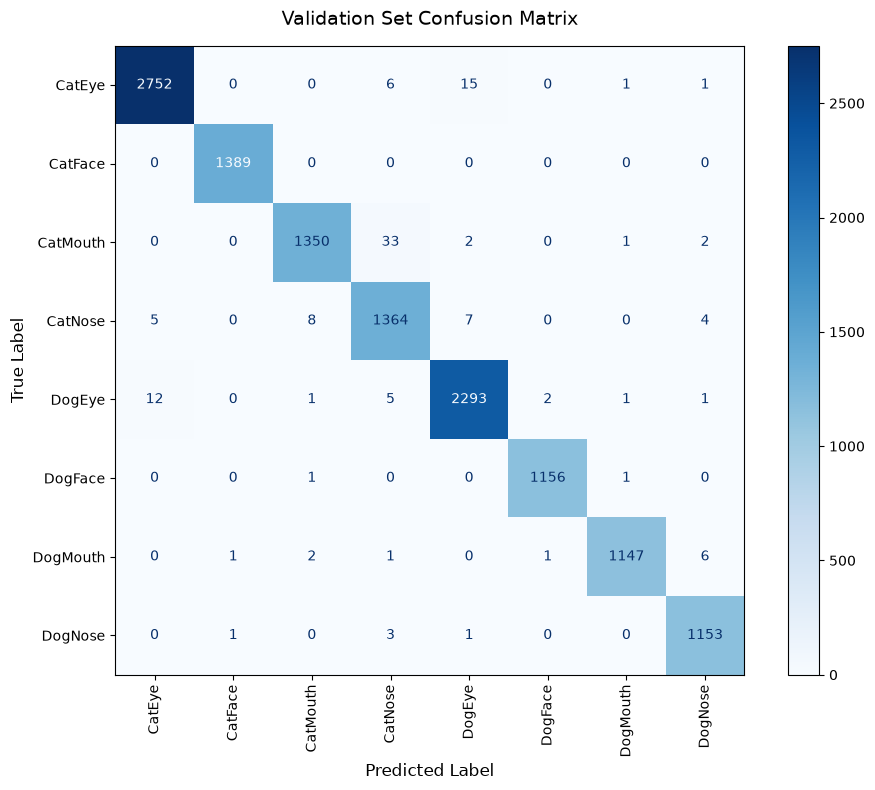

In [36]:
import os
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
import torch
from tqdm import tqdm

# Ensures matplotlib plots render cleanly inside Jupyter Notebooks
%matplotlib inline


def evaluate_model_performance(
    model,
    val_loader,
    device,
    class_names,
    model_path='best_model.pth',
):
  if os.path.exists(model_path):
    print(f'Loading best model weights from {model_path} for evaluation...')
    model.load_state_dict(torch.load(model_path))
  else:
    print(f"Warning: '{model_path}' not found! Evaluating current model state.")

  model = model.to(device)
  model = model.to(memory_format=torch.channels_last)
  model.eval()

  all_preds = []
  all_labels = []

  print('\n--- Running Evaluation on Validation Set ---')
  with torch.no_grad():
    for images, labels in tqdm(val_loader, desc='Evaluating'):
      images = images.to(device, memory_format=torch.channels_last)
      labels = labels.to(device)

      with torch.amp.autocast('cuda'):
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

      all_preds.extend(preds.cpu().numpy())
      all_labels.extend(labels.cpu().numpy())

  # 1. Print detailed classification report (Precision, Recall, F1-Score)
  print('\n================ CLASSIFICATION REPORT ================\n')
  report = classification_report(
      all_labels, all_preds, target_names=class_names, digits=4
  )
  print(report)

  # 2. Compute Confusion Matrix
  cm = confusion_matrix(all_labels, all_preds)

  # 3. Plot Confusion Matrix
  plt.figure(figsize=(10, 8))
  disp = ConfusionMatrixDisplay(
      confusion_matrix=cm, display_labels=class_names
  )
  disp.plot(
      cmap=plt.cm.Blues,
      xticks_rotation='vertical',
      values_format='d',
      ax=plt.gca(),
  )
  plt.title('Validation Set Confusion Matrix', fontsize=14, pad=15)
  plt.xlabel('Predicted Label', fontsize=12)
  plt.ylabel('True Label', fontsize=12)
  plt.tight_layout()
  plt.show()

  return all_labels, all_preds


# --- EXECUTE THE EVALUATION ---
true_labels, predicted_labels = evaluate_model_performance(
    model=model,
    val_loader=val_loader,
    device=device,
    class_names=classes,  # Your list of class names from Task 2
    model_path='best_model.pth',
)

In [ ]:
yes